# DL092 多模态研究的证据与偏差
本Notebook从零重训15个模型到notebook_outputs，不覆盖随包outputs。阅读lecture.md理解标签与统计口径。CPU、合成数据、无需联网。

In [1]:
from pathlib import Path
import json,numpy as np
import experiment as exp
print("NumPy",np.__version__)

NumPy 2.3.5


## 数据与标签
检查真实潜变量仅用于生成和审计，不进入模型。

In [2]:
x,y,g,a=exp.data(8,9201)
print("v, b, z:",x)
print("y:",y)
assert np.array_equal(y,(a*x[:,1]>0).astype(float))

v, b, z: [[-0.20048562  1.         -1.        ]
 [-1.62663509  1.         -1.        ]
 [ 0.60779513 -1.         -1.        ]
 [-0.98743993 -1.          1.        ]
 [-0.67780676 -1.          1.        ]
 [-0.83643128  1.         -1.        ]
 [ 0.9425372   1.          1.        ]
 [ 0.92994856  1.          1.        ]]
y: [0. 0. 0. 1. 1. 0. 1. 1.]


## 手算与特征
确认交互使用带噪视觉v，而非隐藏真值a。

In [3]:
print(exp.features(x,"interaction"))
print("sigmoid(-1.2)=",exp.sigmoid(-1.2))

[[-0.20048562  1.         -1.         -0.20048562  1.        ]
 [-1.62663509  1.         -1.         -1.62663509  1.        ]
 [ 0.60779513 -1.         -1.         -0.60779513  1.        ]
 [-0.98743993 -1.          1.          0.98743993  1.        ]
 [-0.67780676 -1.          1.          0.67780676  1.        ]
 [-0.83643128  1.         -1.         -0.83643128  1.        ]
 [ 0.9425372   1.          1.          0.9425372   1.        ]
 [ 0.92994856  1.          1.          0.92994856  1.        ]]
sigmoid(-1.2)= 0.23147521650098238


## 完整真实训练
运行五种方法、三种子、八个测试条件。

In [4]:
result=exp.main("notebook_outputs")
print(json.dumps(result["aggregate"],indent=2))

{
  "seconds": 0.411231071993825,
  "paired_delta": -0.30666666666666664,
  "ci": [
    -0.3375104166666667,
    -0.275
  ],
  "reload_error": 0.0
}
[
  {
    "method": "vision",
    "domain": "iid",
    "error_mean": 0.49625,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "shortcut_flip",
    "error_mean": 0.49625,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "shortcut_random",
    "error_mean": 0.49625,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "missing_vision",
    "error_mean": 0.4675,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "missing_text",
    "error_mean": 0.49625,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "question_counterfactual",
    "error_mean": 0.50375,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "permuted_original_label",
    "error_mean": 0.49625,
    "seed_sd": 0.0
  },
  {
    "method": "vision",
    "domain": "permuted_relabelled",
   

## 配对与重标
相同输入可有不同评价问题。先明确标签规则再看准确率。

In [5]:
ds=exp.domains(x,y,a)
print("original:",ds["permuted_original_label"][1])
print("relabelled:",ds["permuted_relabelled"][1])
print("delta",result["paired_delta"],"CI",result["paired_example_bootstrap_ci"])

original: [0. 0. 0. 1. 1. 0. 1. 1.]
relabelled: [1. 0. 0. 0. 1. 0. 1. 1.]
delta -0.30666666666666664 CI [-0.3375104166666667, -0.275]


## 自动测试
有限差分检查手写梯度，也检查反事实标签。

In [6]:
import unittest
suite=unittest.defaultTestLoader.discover(".",pattern="test_experiment.py")
check=unittest.TextTestRunner(verbosity=2).run(suite)
if not check.wasSuccessful(): raise RuntimeError("test failure")

test_bootstrap_constant (test_experiment.TestEvidence.test_bootstrap_constant) ... 

ok


test_counterfactual (test_experiment.TestEvidence.test_counterfactual) ... 

ok


test_features (test_experiment.TestEvidence.test_features) ... 

...

test_shape (test_experiment.TestEvidence.test_shape) ... 

ok


test_training_determinism (test_experiment.TestEvidence.test_training_determinism) ... 

ok


----------------------------------------------------------------------
Ran 13 tests in 0.022s

OK


## 直接从本次运行绘制诊断
此图使用notebook_outputs对应的result，避免混用随包结果。

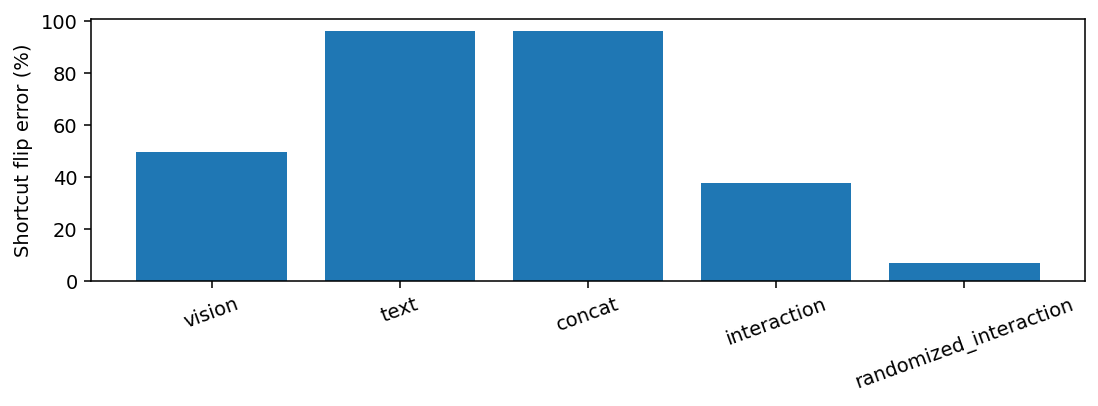

In [7]:
import matplotlib.pyplot as plt
from IPython.display import display, Image
import io
fig,ax=plt.subplots(figsize=(8,3))
rows=[r for r in result["aggregate"] if r["domain"]=="shortcut_flip"]
ax.bar([r["method"] for r in rows],[100*r["error_mean"] for r in rows])
ax.set_ylabel("Shortcut flip error (%)")
ax.tick_params(axis="x",rotation=20)
fig.tight_layout()
buf=io.BytesIO()
fig.savefig(buf,format="png",dpi=140,bbox_inches="tight")
display(Image(data=buf.getvalue()))
plt.close(fig)

## 写下结论
记录一个支持的比较、一项原域代价、一项无法外推的结论。不要把三种子误称为三个独立现实数据集。